> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Módulo 54 · Introducción a las series de tiempo
**IBM y Walmart (WMT) | Javier Bueno Sánchez**  
Datos diarios de Yahoo Finance, ventana solicitada: 27-09-2021 al 27-09-2026 (extremo final exclusivo 28-09-2026). La última sesión disponible se informa al ejecutar. Este cuaderno y el PDF documentan resultados obtenidos, y los CSV adjuntos permiten reproducirlos sin conexión.

**Criterio:** cierre ajustado (`Adj_Close`) para tratar divisiones y dividendos históricos. El precio de cierre sin ajustar está disponible en los CSV. Precios en USD por acción; rendimientos diarios adimensionales. Yahoo puede revisar ajustes históricos; esta entrega es una fotografía de la descarga.

In [1]:
import pathlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.tsa.seasonal import seasonal_decompose
from IPython.display import display
BASE=pathlib.Path('M54_IBM_Walmart') if pathlib.Path('M54_IBM_Walmart').exists() else pathlib.Path('.')
raw={t:pd.read_csv(BASE/f'{t}_Yahoo_2021-2026.csv',parse_dates=['Date']).set_index('Date') for t in ['IBM','WMT']}
prices=pd.concat({t:raw[t]['Adj_Close'] for t in raw},axis=1).dropna().sort_index()
returns=prices.pct_change().dropna()
print('Período común:',prices.index.min().date(),'-',prices.index.max().date(),'| sesiones:',len(prices))
display(prices.describe().round(2))

Período común: 2021-09-27 - 2026-09-25 | sesiones: 1255
           IBM      WMT
count  1255.00  1255.00
mean    178.47    71.73
std      63.96    28.45
min      96.92    37.47
25%     117.63    46.71
50%     163.21    58.41
75%     235.94    96.93
max     326.89   133.88


## 1. Componentes y nomenclatura
Una serie de tiempo es una sucesión de observaciones indexadas por fecha. En la descomposición aditiva $P_t=T_t+S_t+R_t$, $T_t$ es tendencia suavizada, $S_t$ patrón repetitivo respecto al período elegido y $R_t$ es residuo. Un ciclo económico plurianual no se identifica con una supuesta estacionalidad semanal. El mercado no cotiza todos los días calendario: la posición sucesiva representa **sesiones bursátiles**, no días naturales. Los cierres ajustados no son precios directamente transables para una orden futura.

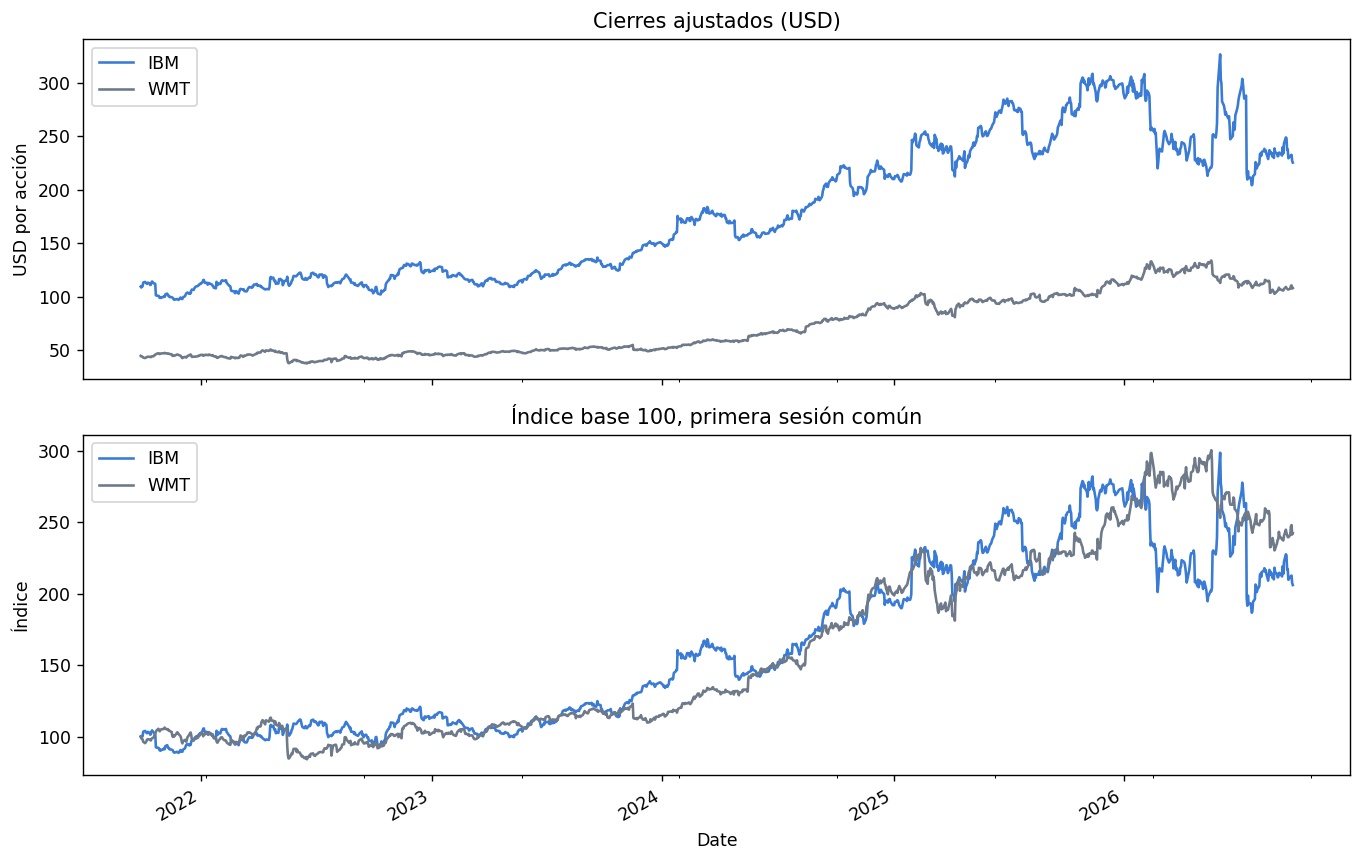

In [2]:
fig,ax=plt.subplots(2,1,figsize=(11,7),sharex=True)
prices.plot(ax=ax[0],color=['#3A7BD5','#6E7A89']);ax[0].set_title('Cierres ajustados (USD)');ax[0].set_ylabel('USD por acción')
(prices/prices.iloc[0]*100).plot(ax=ax[1],color=['#3A7BD5','#6E7A89']);ax[1].set_title('Índice base 100, primera sesión común');ax[1].set_ylabel('Índice');plt.tight_layout();plt.show()

## 2. Asociación entre IBM y Walmart
Pearson mide asociación lineal contemporánea. Se informa tanto en niveles como en cambios porcentuales diarios: una correlación alta en precios con tendencia **no demuestra** que los movimientos diarios se acompañen ni que uno cause al otro. La gráfica de rendimientos usa una línea de referencia en cero.

Pearson en precios ajustados: 0.9286; Pearson en rendimientos diarios: 0.1069


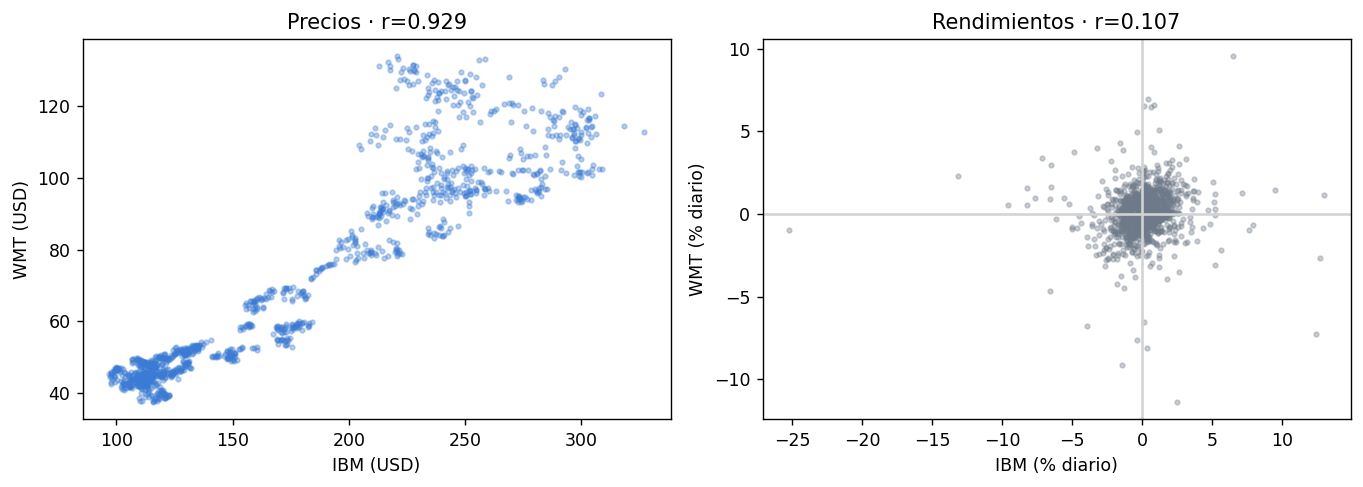

In [3]:
level_r=prices['IBM'].corr(prices['WMT']);return_r=returns['IBM'].corr(returns['WMT'])
print(f'Pearson en precios ajustados: {level_r:.4f}; Pearson en rendimientos diarios: {return_r:.4f}')
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(prices.IBM,prices.WMT,s=7,alpha=.35,color='#3A7BD5');ax[0].set(xlabel='IBM (USD)',ylabel='WMT (USD)',title=f'Precios · r={level_r:.3f}')
ax[1].scatter(returns.IBM*100,returns.WMT*100,s=7,alpha=.35,color='#6E7A89');ax[1].axhline(0,color='lightgray');ax[1].axvline(0,color='lightgray');ax[1].set(xlabel='IBM (% diario)',ylabel='WMT (% diario)',title=f'Rendimientos · r={return_r:.3f}')
plt.tight_layout();plt.show()

## 3. Descomposición y correlogramas
Se utiliza `period=5` como aproximación didáctica a una semana de **cinco sesiones**. Feriados y cierres pueden romper esa correspondencia; este componente no demuestra una estacionalidad negociable. La ACF muestra correlación de la serie con sus rezagos; la banda aproximada $\pm1.96/\sqrt{n}$ sirve de referencia bajo un proceso de ruido blanco, condición que los precios en niveles no suelen cumplir. También se presenta ACF de rendimientos para reducir el efecto de la tendencia.

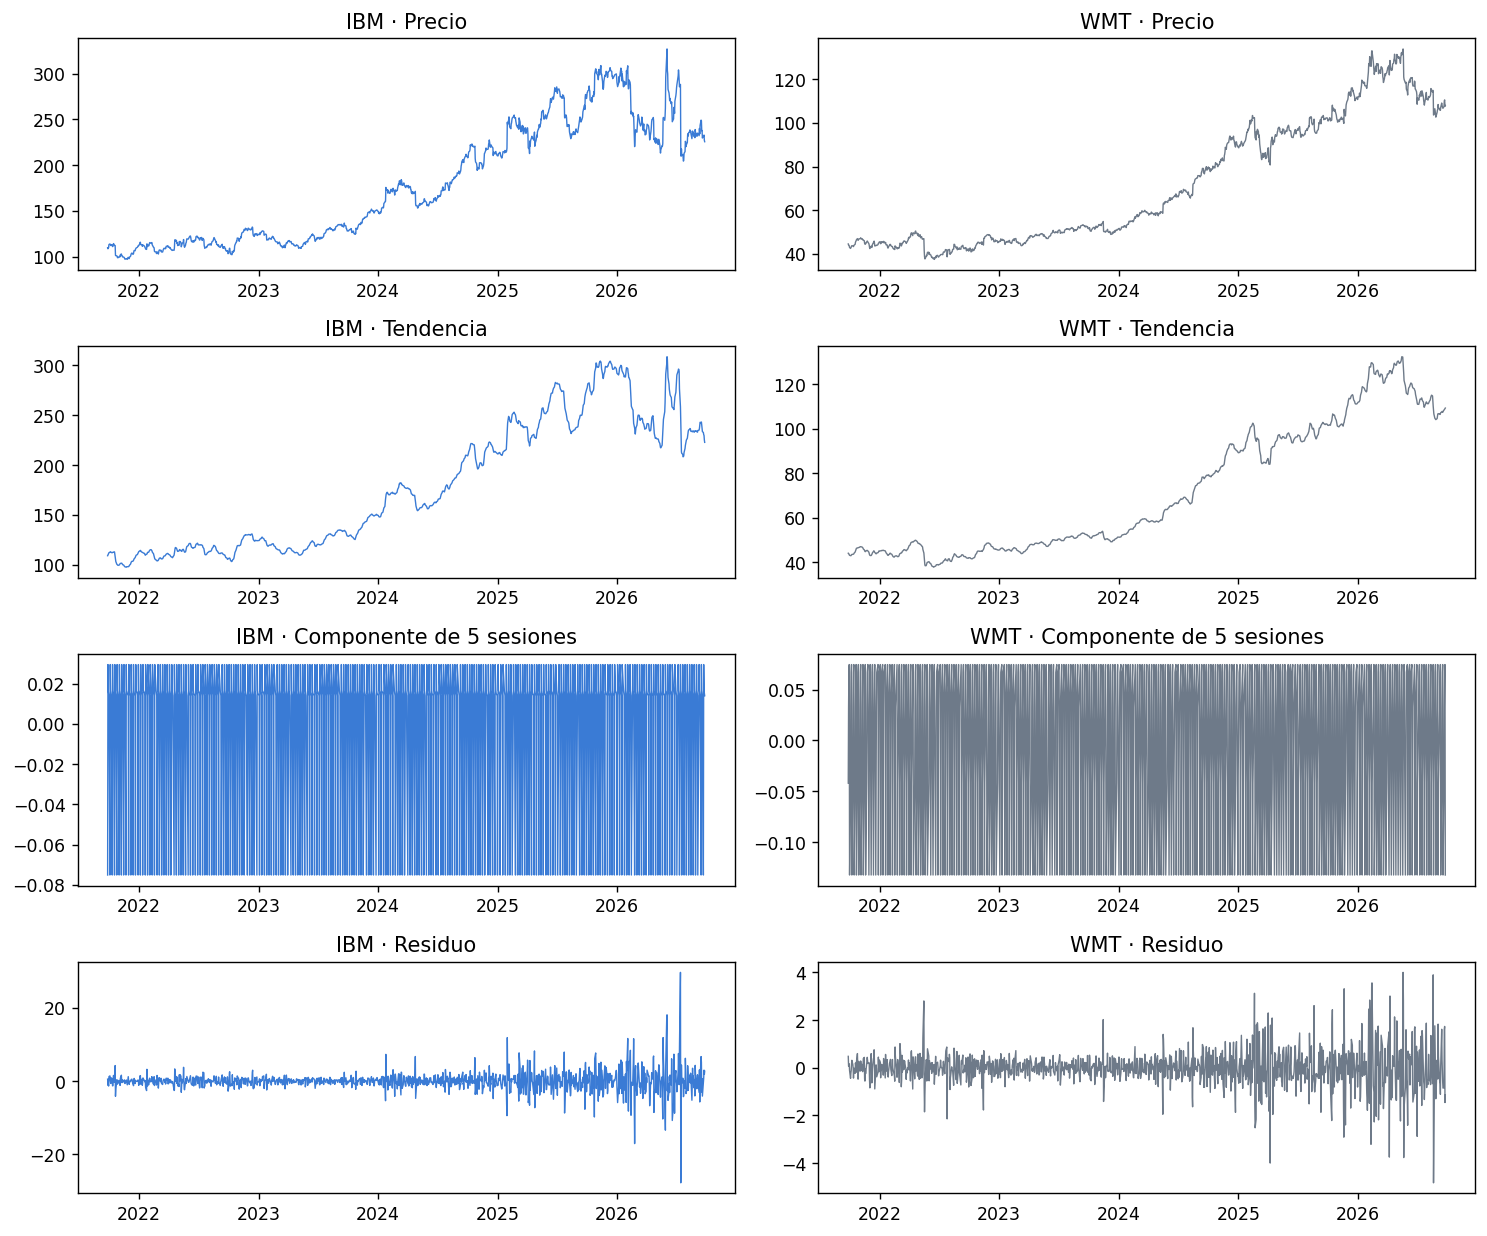

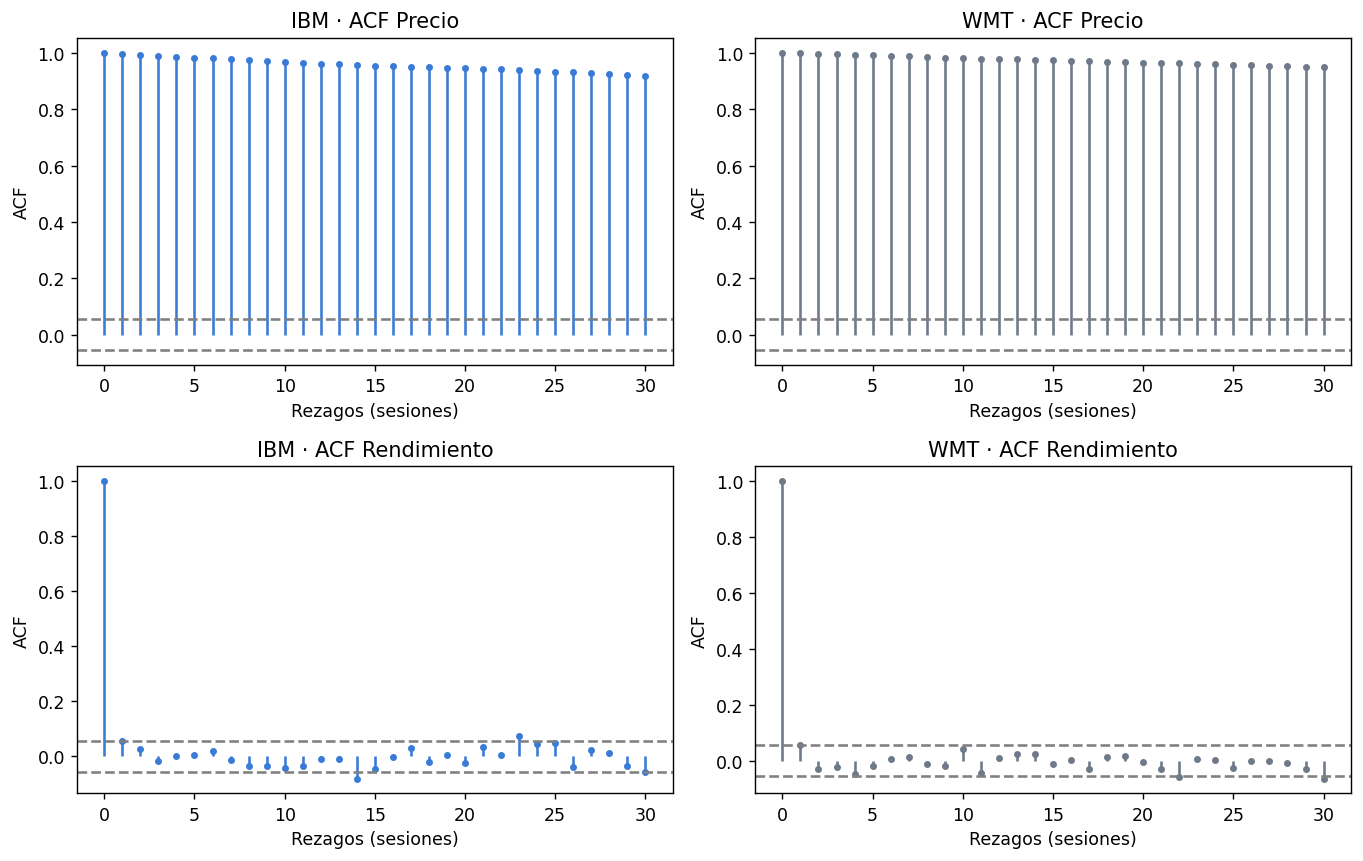

In [4]:
fig,axes=plt.subplots(4,2,figsize=(12,10))
for j,t in enumerate(['IBM','WMT']):
 dec=seasonal_decompose(prices[t],model='additive',period=5,extrapolate_trend='freq')
 for i,(s,lab) in enumerate([(prices[t],'Precio'),(dec.trend,'Tendencia'),(dec.seasonal,'Componente de 5 sesiones'),(dec.resid,'Residuo')]):
  axes[i,j].plot(prices.index,s,color=['#3A7BD5','#6E7A89'][j],lw=.8)
  axes[i,j].set_title(f'{t} · {lab}')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(2,2,figsize=(11,7))
for j,t in enumerate(['IBM','WMT']):
 for i,(s,lab) in enumerate([(prices[t],'Precio'),(returns[t],'Rendimiento')]):
  v=acf(s,nlags=30,fft=True);ax[i,j].stem(range(len(v)),v,linefmt=['#3A7BD5','#6E7A89'][j],markerfmt='.',basefmt=' ')
  ax[i,j].axhline(1.96/np.sqrt(len(s)),color='gray',ls='--');ax[i,j].axhline(-1.96/np.sqrt(len(s)),color='gray',ls='--')
  ax[i,j].set(title=f'{t} · ACF {lab}',xlabel='Rezagos (sesiones)',ylabel='ACF')
plt.tight_layout();plt.show()

## 4. Dickey-Fuller aumentado (ADF)
$H_0$: la serie tiene raíz unitaria; $H_1$: es estacionaria en el sentido del modelo de la prueba. Se fija `regression="c"` (constante, sin tendencia determinista explícita) y `autolag="AIC"`; umbral 5 %. Un $p>0.05$ significa **no rechazar** $H_0$, no demostrarla. El resultado depende de especificación y período. Repetimos en rendimientos como diagnóstico complementario.

In [5]:
adf_rows=[]
for t in ['IBM','WMT']:
 for name,series in [('Precio',prices[t]),('Rendimiento',returns[t])]:
  a=adfuller(series,regression='c',autolag='AIC')
  adf_rows.append([t,name,a[0],a[1],a[2],a[3],'Rechazar H0' if a[1]<.05 else 'No rechazar H0'])
adf_table=pd.DataFrame(adf_rows,columns=['Empresa','Serie','ADF','p','Rezagos','N','Decisión al 5 %'])
display(adf_table.round(4))

  Empresa        Serie      ADF       p  Rezagos     N Decisión al 5 %
0     IBM       Precio  -1.0521  0.7338       15  1239  No rechazar H0
1     IBM  Rendimiento -33.4945  0.0000        0  1253     Rechazar H0
2     WMT       Precio  -0.4908  0.8938        2  1252  No rechazar H0
3     WMT  Rendimiento -33.4078  0.0000        0  1253     Rechazar H0


## 5. Promedios móviles y pronóstico fuera de muestra
Media móvil causal de $k$ sesiones: $\hat P_{t+1}^{(k)}=\frac1k\sum_{i=0}^{k-1}P_{t-i}$. Se comparan $k=5$ y $k=20$ con el último precio (`k=1`) como referencia. Los últimos 60 cierres de cada serie son prueba. Para cada fecha de prueba, el cálculo utiliza **únicamente los cierres anteriores**; no incorpora el cierre que intenta pronosticar. Se reportan MAE (USD) y MAPE (%). Tras la evaluación, se usa toda la serie disponible para pronosticar la siguiente **sesión**; el calendario de feriados no se infiere del índice diario.

  Empresa  Ventana  MAE USD  MAPE %
0     IBM        1    5.206   2.240
1     IBM        5    9.180   3.994
2     IBM       20   16.900   7.436
3     WMT        1    1.317   1.206
4     WMT        5    1.853   1.704
5     WMT       20    2.867   2.646
IBM: último cierre 225.51 USD; pronóstico MA(5) 229.73, MA(20) 235.12; menor MAE en prueba: MA(1).
WMT: último cierre 107.98 USD; pronóstico MA(5) 108.73, MA(20) 107.11; menor MAE en prueba: MA(1).


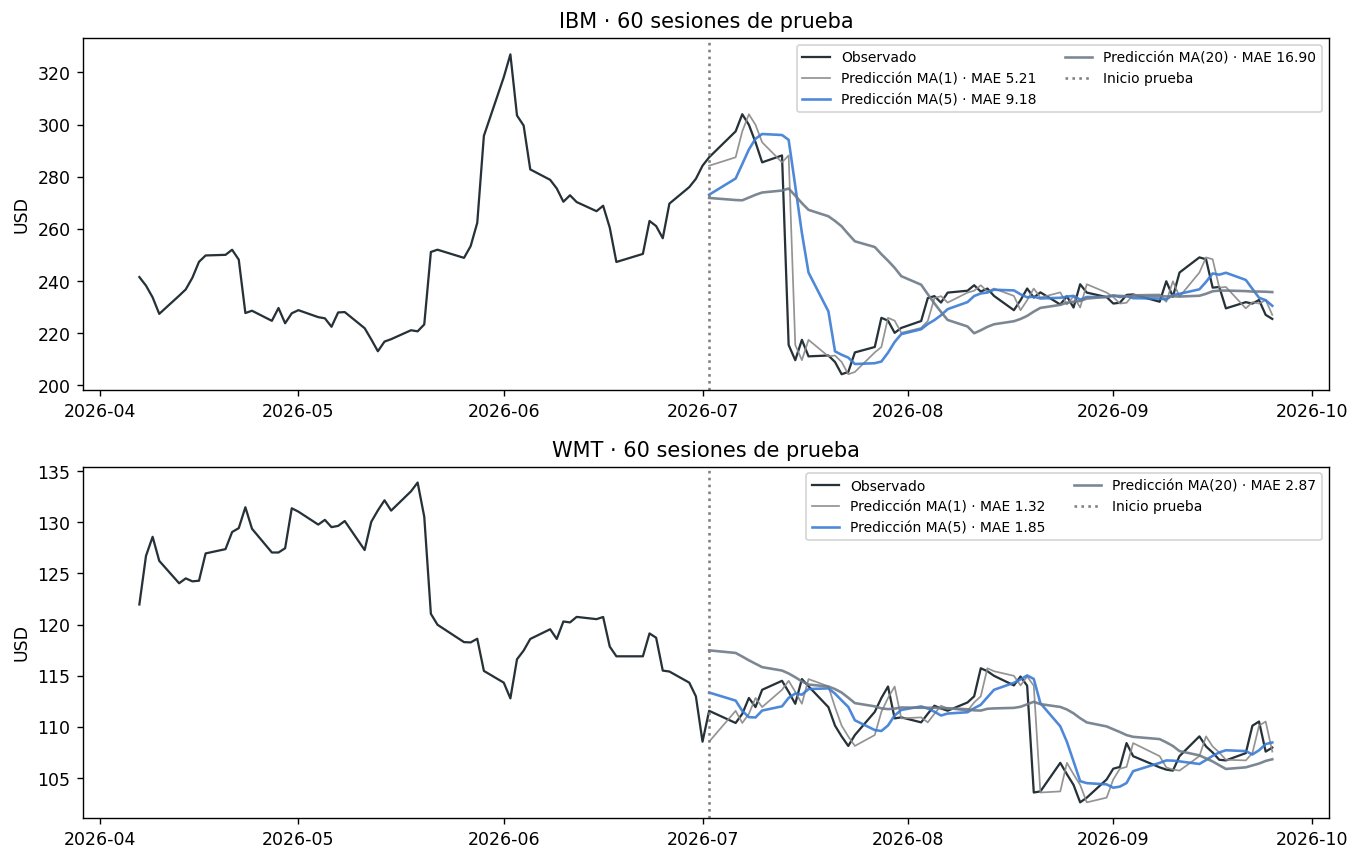

In [6]:
rows=[]; forecasts={};fig,ax=plt.subplots(2,1,figsize=(11,7))
for i,t in enumerate(['IBM','WMT']):
 s=prices[t];target=s.iloc[-60:];ax[i].plot(s.iloc[-120:],label='Observado',color='#263238',lw=1.3)
 for k,c in [(1,'#888888'),(5,'#3A7BD5'),(20,'#6E7A89')]:
  pred=s.shift(1).rolling(k).mean().loc[target.index]
  mae=(target-pred).abs().mean();mape=((target-pred).abs()/target).mean()*100
  rows.append([t,k,mae,mape]);forecasts[(t,k)]=s.tail(k).mean()
  ax[i].plot(pred,label=f'Predicción MA({k}) · MAE {mae:.2f}',alpha=.9,color=c,lw=1 if k==1 else 1.5)
 ax[i].axvline(target.index[0],color='gray',ls=':',label='Inicio prueba');ax[i].set(title=f'{t} · 60 sesiones de prueba',ylabel='USD');ax[i].legend(ncol=2,fontsize=8)
plt.tight_layout();plt.show()
metrics=pd.DataFrame(rows,columns=['Empresa','Ventana','MAE USD','MAPE %']);display(metrics.round(3))
for t in ['IBM','WMT']:
 best=metrics[metrics.Empresa==t].sort_values('MAE USD').iloc[0]
 print(f'{t}: último cierre {prices[t].iloc[-1]:.2f} USD; pronóstico MA(5) {forecasts[t,5]:.2f}, MA(20) {forecasts[t,20]:.2f}; menor MAE en prueba: MA({int(best.Ventana)}).')

## Conclusiones y límites
- Los diagramas y Pearson permiten describir asociación histórica; la correlación en rendimientos responde mejor a la pregunta sobre movimientos diarios. Ninguna correlación establece causalidad.
- La descomposición con cinco sesiones es una ilustración descriptiva. La ACF de precios puede reflejar persistencia y tendencia, y no constituye por sí sola evidencia de estacionalidad o utilidad predictiva.
- ADF se interpreta por su hipótesis nula y su valor p, separadamente para precios y rendimientos.
- El pronóstico del siguiente día es un promedio calculado **antes** de conocer ese cierre. La comparación de prueba con la referencia de último cierre decide si el promedio móvil aporta valor. Incluso un MAPE bajo puede coexistir con errores de dirección o saltos de cotización: no es un modelo de inversión ni un intervalo de confianza.

**Fuente:** Yahoo Finance, API pública de gráficos diarios (`/v8/finance/chart/IBM` y `/WMT`), descargada para esta actividad. Los archivos CSV conservan la fotografía usada. Bibliotecas: pandas, statsmodels, matplotlib.